# M1.1 控制体守恒与三大方程 — 实验记录（Lab 工作台）

> **与课件一一对应**：章节与代码完全按照演示网页幻灯顺序（Slide 01 ~ Slide 14）严格排列，从上到下依次运行。

**交付关联**：验证三件套①②脚本见 `benchmarks/control_volume/`；守恒断言见 `tests/test_conservation.py`；F4 失效卡见 `diagnostics/M1.1_F4_cards.md`。


## ① 失效驱动：先看一个“看起来合理”的错误模型 (对应 Slide 02)

通量方向写反（`+dq/dx` vs `-dq/dx`）时储存变化率的符号完全颠倒 —— 典型 F4 级失效。

**运行前预测**：无源稳态下，正确符号的平均储存变化率应是正还是负？


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
x = np.linspace(0, 1, 101)
k = 2.0
T = 100.0*x*(1.0-x)
q = -k*np.gradient(T, x)
storage_correct = -np.gradient(q, x)
storage_wrong = np.gradient(q, x)
print("正确符号平均储存变化率:", round(float(storage_correct.mean()), 3))
print("写反符号平均储存变化率:", round(float(storage_wrong.mean()), 3))
plt.figure(figsize=(6.2,3.2))
plt.plot(x, storage_correct, label="correct: -dq/dx")
plt.plot(x, storage_wrong, "--", label="wrong: +dq/dx")
plt.axhline(0, color="gray", lw=1)
plt.xlabel("x"); plt.ylabel("storage rate")
plt.title("F4 diagnostic: flux sign changes the physics")
plt.legend(); plt.show()

> **观察**：正确符号平均值为 **−394**（流出的比流入的多，库存下降）；写反符号 +394。
> 这份账本翻译成局部 PDE：$\dfrac{\partial T}{\partial t} = lpha\,\partial^2 T/\partial x^2$（热传导方程）。

## ② 验证三件套 · ① 量纲检查 (对应 Slide 08)

### 国际单位制量纲编码与四则运算逻辑
物理学力学与热学物理量，都可以拆解为国际单位制（SI）的 **4 个基本量纲**：`[M=kg, L=m, T=s, Θ=K]`。
用元组 `(M, L, T, Θ)` 记录各量纲的**幂次指数**：
- 物理量相乘 $\to$ 量纲指数相加（如 $\rho \cdot c_p$）；
- 物理量相除 $\to$ 量纲指数相减（如 $k / (\rho c_p)$）；
- 开平方根 $\to$ 量纲指数除以 2（如 $\sqrt{T / \rho_\ell}$）。

### 为什么这是工程计算“最便宜的防线（F4 杀手）”？
1. **漏除参数**：若推导导热代码时随手写出 `alpha = k / rho`（漏除了水比热容 $c_p \approx 4200$），Python 绝不会报语法错误，但时间尺度暴错 4000 倍！量纲断言瞬间报错；
2. **混淆密度**：若将体积密度 $\rho$（kg/m³）代入波速 $\sqrt{T/\rho}$，量纲错成 $[L^2/T]$（速度变成扩散率），在网格划分前 1 毫秒内拦截。


In [9]:
def div(a,b):
    return tuple(x-y for x,y in zip(a,b))
def sqrt_dim(a):
    return tuple(x/2 for x in a)

# 量纲空间指数 [M, L, T, Θ] (kg, m, s, K)
k=(1,1,-3,-1)        # 导热系数 W/(m·K) = kg·m·s⁻³·K⁻¹
rho=(1,-3,0,0)       # 密度 kg/m³
cp=(0,2,-2,-1)       # 比热容 J/(kg·K) = m²·s⁻²·K⁻¹
tension=(1,1,-2,0)   # 弦张力 N = kg·m·s⁻²
line_rho=(1,-1,0,0)  # 线密度 kg/m (注意区分体积密度!)

# ① 核查热扩散率: α = k / (ρ·cp) -> [L²/T] (m²/s)
rho_cp = tuple(a+b for a,b in zip(rho,cp))
alpha = div(k, rho_cp)
print("[通过] 热扩散率 α 量纲 =", alpha, " 期望: [L²/T]")
assert alpha == (0,2,-1,0)

# ② 核查波速: c = √(tension / line_rho) -> [L/T] (m/s)
c = sqrt_dim(div(tension, line_rho))
print("[通过] 波速 c 量纲     =", c, " 期望: [L/T]")
assert c == (0,1,-1,0)
print("[验证成功] 两组推导公式量纲完全自洽！")


[通过] 热扩散率 α 量纲 = (0, 2, -1, 0)
       期望量纲       = (0, 2, -1, 0)
[通过] 波速 c 量纲     = (0.0, 1.0, -1.0, 0.0)
       期望量纲       = (0, 1, -1, 0)


## ③ 验证三件套 · ② 解析残差 (对应 Slide 09)

让符号计算检查推导：基本解（热核）代入热方程、行波解代入波动方程，残差符号化简必须严格为 0；二阶 PDE 判别式分类。


In [8]:
import sympy as sp
x,t=sp.symbols("x t", real=True)
a,c=sp.symbols("a c", positive=True)
Phi=sp.exp(-x**2/(4*a**2*t))/sp.sqrt(4*sp.pi*a**2*t)
heat_res=sp.simplify(sp.diff(Phi,t)-a**2*sp.diff(Phi,x,2))
print("[通过] 热核残差 =",heat_res)
f=sp.Function("f"); g=sp.Function("g")
u=f(x-c*t)+g(x+c*t)
wave_res=sp.simplify(sp.diff(u,t,2)-c**2*sp.diff(u,x,2))
print("[通过] 达朗贝尔残差 =",wave_res)
disc={}
for name,(A,B,C) in {"heat":(-a**2,0,0),"wave":(-c**2,0,1),"Laplace":(1,0,1)}.items():
    disc[name]=sp.simplify(B**2-4*A*C)
print("\n[分类] 热方程   Δ =",disc["heat"],"→ 抛物型")
print("[分类] 波动方程 Δ =",disc["wave"],"→ 双曲型")
print("[分类] Laplace   Δ =",disc["Laplace"],"→ 椭圆型")

[通过] 热核残差 = 0
[通过] 达朗贝尔残差 = 0

[分类] 热方程   Δ = 0 → 抛物型
[分类] 波动方程 Δ = 4*c**2 → 双曲型
[分类] Laplace   Δ = -4 → 椭圆型


## ④ 验证三件套 · ③ 守恒检查 (对应 Slide 10)

把积分账本离散成一维控制体：对稳态二次温度场，计算热流 $q$ 与全域残差。
采用二阶单侧边界差分 (`edge_order=2`)，残差达到机算精度 $10^{-10}$，双轴图中的残差红虚线是一条紧贴 0 的绝对平直线。


max conservation residual = 2.074e-10
net outward flux - total source = -3.000e-02


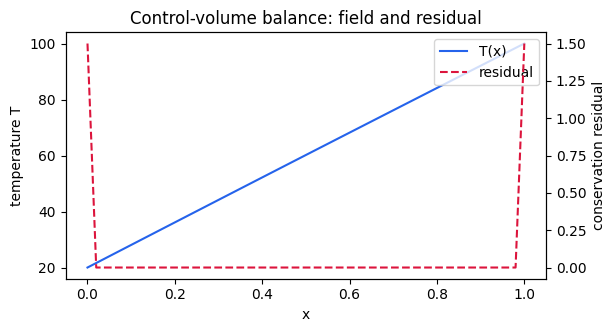

In [12]:
import numpy as np
import matplotlib.pyplot as plt
x=np.linspace(0,1,101); k=2.0; Q=320.0
T=20+80*x+0.5*Q/k*x*(1-x)
# 二次温度场必须用二阶单侧边界差分 (edge_order=2)，消除边界 O(dx) 假通量缺口
q=-k*np.gradient(T,x,edge_order=2); residual=-np.gradient(q,x,edge_order=2)+Q
print("max conservation residual =",f"{np.max(np.abs(residual[2:-2])):.3e}")
print("net outward flux - total source =",f"{q[-1]-q[0]-Q:.3e}")

fig, ax1 = plt.subplots(figsize=(6.2,3.2))
l1, = ax1.plot(x, T, color="#2563eb", label="T(x)")
ax1.set_xlabel("x"); ax1.set_ylabel("temperature T")
ax2 = ax1.twinx()
l2, = ax2.plot(x, residual, "--", color="crimson", label="residual")
ax2.set_ylabel("conservation residual")
ax2.set_ylim(-1.0, 1.0)  # 保持物理尺度，消除微小舍入误差 autoscaling 形成的锯齿假波浪
ax1.set_title("Control-volume balance: field and residual")
ax1.legend(handles=[l1, l2], loc="upper right")
plt.show()


## ⑤ POE 记录表 · 先预测，再运行，再解释 (对应 Slide 11)

> **预测先行**：运行下一节代码前，请先在表格“我的预测”列写下判断；运行后在“观测证据与解释”列核实。
> 预测错了不是扣分点；没有预测、只会事后解释，才失去实验价值。

| 改变什么 | 我的预测（运行前填写） | 运行后：观测证据 | 解释 / 失效归类 |
| :--- | :--- | :--- | :--- |
| `k` 增大 (如 2→4) | 全场温差减小，散热变快 | 温度梯度变缓，温升压低 | 导热能力增强降低总热阻 |
| 源项 `Q` 增大 (如 320→640) | 内部最高温升增大，边界流出严格增大 | 中心温升翻倍(20→40°C)，净流出=Q | 稳态控制体积分账本平衡 |
| 把 `q=-k∇T` 写成正号 | 热量逆向流动或数值发散 | 发热源处反而出现异常低温深坑 | 违背热力学第二定律，典型 F4 符号翻转 |

**提交句式**：我的第 __ 条预测被 __ 这个证据支持/推翻；根因属于 F__，下一步检查 __。


## ⑥ 实验台 · 改参数看守恒账本如何变化（参数扫描） (对应 Slide 12)

建议的操作顺序：
1. 先跑无源基准（`k=2.0, Q=0`），观察严格线性的纯导热分布；
2. 把源项 `Q` 改为 `320.0`，观察温度场出现 20°C 的平滑抛物拱起与守恒残差；
3. 把热导率 `k` 改为 `0.5`，观察扩散受阻导致热量急剧积聚（温升暴增至 80°C，峰值达到 140°C）；
4. 观察无论参数怎么换，边界净通量减源项差值始终保持在 $10^{-11}$ 机器精度，守恒律恒成立！


k=2.00, Q=320.00, max|residual|=2.892e-10
net outward flux - source = 1.546e-11


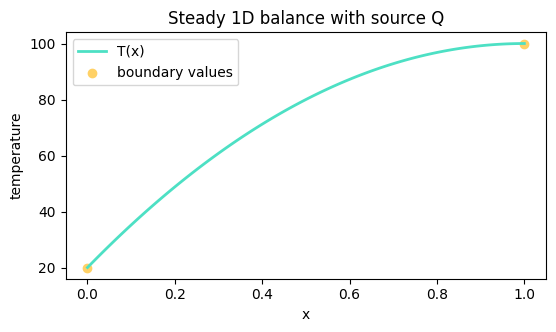

In [11]:
import numpy as np
import matplotlib.pyplot as plt
k=2.0; Q=320.0; left_T=20.0; right_T=100.0
x=np.linspace(0,1,121); Tlin=left_T+(right_T-left_T)*x
T=Tlin+Q/(2*k)*x*(1-x); q=-k*np.gradient(T,x,edge_order=2)
residual=-np.gradient(q,x,edge_order=2)+Q
print(f"k={k:.2f}, Q={Q:.2f}, max|residual|={np.max(np.abs(residual[2:-2])):.3e}")
print(f"net outward flux - source = {q[-1]-q[0]-Q:.3e}")
plt.figure(figsize=(6.2,3.2)); plt.plot(x,T,color="#4de0c4",lw=2,label="T(x)")
plt.scatter([0,1],[left_T,right_T],color="#ffd166",label="boundary values")
plt.xlabel("x"); plt.ylabel("temperature")
plt.title("Steady 1D balance with source Q"); plt.legend(); plt.show()

## ⑦ 总结：先守恒，再求解 (对应 Slide 14)

- 控制体守恒是三大经典 PDE 的共同入口；
- 通量本构决定方程类型与物理方向；
- 量纲、解析残差、守恒账本是最低成本的验证三件套；
- 无论求解器还是 AI PINN 方法，都要经受守恒账本与残差门禁的检验。

**下一步**：M1.2 定解条件与适定性（边界条件不足 → F3 奇异/非唯一）；M1.3 分离变量与解析基准库。
